Last two digits of Student ID (d): 47
Observed: ['C', 'C++', 'Java', 'Python'] [67 32 35 37]
H0: Students have an equal preference for all four languages
H1: Students do not have an equal preference for all four languages
Total: 171
Expected: [42.75 42.75 42.75 42.75]
Chi-square statistic: 18.637
Degrees of freedom: 3
Critical value (0.05 level): 7.815
P-value: 0.0003
Reject H0.
Conclusion: Students do NOT have an equal preference for the four programming languages.


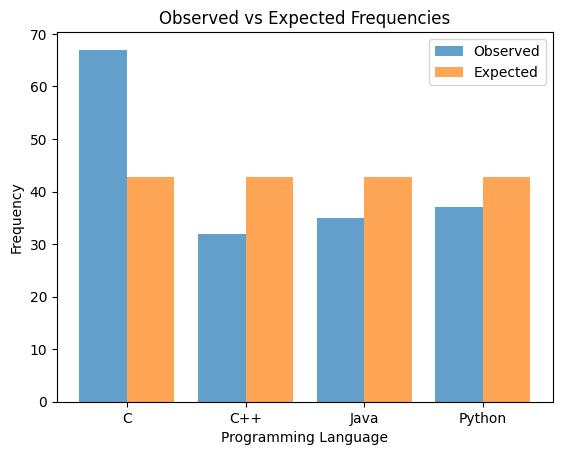

In [6]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# Step 0: last two digits of your Student ID
d = 47
print("Last two digits of Student ID (d):", d)

# Step 1: Observed frequencies
languages = ['C', 'C++', 'Java', 'Python']
observed = np.array([
    20 + d,
    25 + (d % 10),
    30 + (d % 7),
    35 + (d % 5)
])
print("Observed:", languages, observed)

# Hypotheses
print("H0: Students have an equal preference for all four languages")
print("H1: Students do not have an equal preference for all four languages")

# Step 2: Expected frequencies (uniform)
total = np.sum(observed)
expected = np.full(len(observed), total / len(observed), dtype=float)  # dtype=float so 39.5 isn't truncated to 39
print("Total:", total)
print("Expected:", expected)

# Step 3: Chi-square statistic
chi_square_stat = np.sum(((observed - expected) ** 2) / expected)

# Step 4: Degrees of freedom
df = len(observed) - 1

# Step 5: Critical value and p-value
alpha = 0.05
critical_value = stats.chi2.ppf(1 - alpha, df)
p_value = 1 - stats.chi2.cdf(chi_square_stat, df)

# Results
print(f'Chi-square statistic: {chi_square_stat:.3f}')
print(f'Degrees of freedom: {df}')
print(f'Critical value (0.05 level): {critical_value:.3f}')
print(f'P-value: {p_value:.4f}')

# Decision and conclusion
if chi_square_stat > critical_value:
    print('Reject H0.')
    print('Conclusion: Students do NOT have an equal preference for the four programming languages.')
else:
    print('Fail to reject H0.')
    print('Conclusion: There is no significant evidence against equal preference among the four languages.')

# Plot
x = np.arange(1, len(observed) + 1)
plt.bar(x, observed, width=0.4, label='Observed', alpha=0.7)
plt.bar(x + 0.4, expected, width=0.4, label='Expected', alpha=0.7)
plt.xticks(x + 0.2, languages)
plt.xlabel('Programming Language')
plt.ylabel('Frequency')
plt.title('Observed vs Expected Frequencies')
plt.legend()
plt.show()